# The economics of a trade

Reconcile published trades and compare their screened rankings.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

Published candidate count: 3680 · Batch date: 2026-11-13


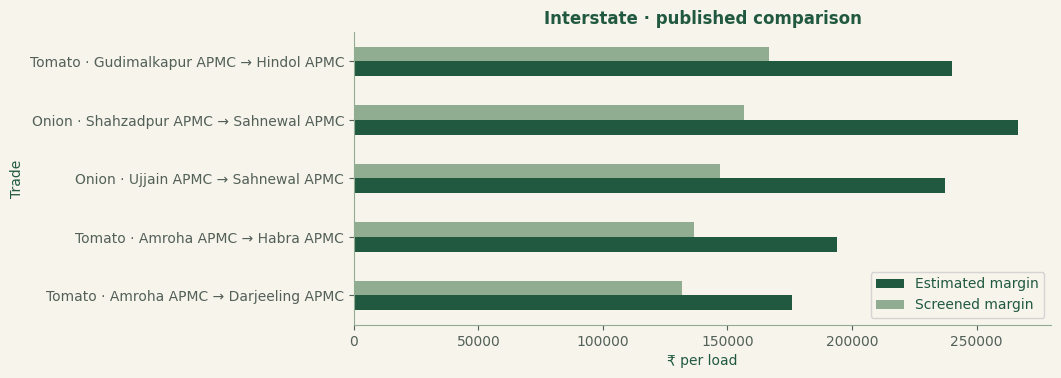

Buy Gudimalkapur APMC · Sell Hindol APMC · 100 q loaded · 97.50 q saleable


,Project calculation (₹ unless shown)
Price spread (₹/q),2900.00
Procurement,90000.00
Transport,38391.50
Handling,1800.00
Storage,0.00
Total cost,130191.50
Sale revenue,370500.00
Net margin,240308.50
Screened margin,166549.77


interactive(children=(Dropdown(description='Mode', options=('interstate', 'intrastate'), value='interstate'), …

In [2]:
saved = auxiliary("strategies")
rows = saved["rows"]
print("Published candidate count:", saved["candidate_count"], "· Batch date:", saved["date"])

def trade_view(mode):
    chosen = [r for r in rows if r["trading_mode"] == mode][:5]
    if not chosen:
        print("No saved strategy for this mode.")
        return
    table = pd.DataFrame({
        "Trade": [f"{r['crop']} · {r['buy']['market']} → {r['sell']['market']}" for r in chosen],
        "Estimated margin": [r["margin"] for r in chosen],
        "Screened margin": [r["risk_adjusted_margin"] for r in chosen],
    }).set_index("Trade")
    table.iloc[::-1].plot.barh(title=mode.title()+" · published comparison", xlabel="₹ per load")
    plt.show()
    row = chosen[0]
    saleable = row["quantity_q"]*(1-row["loss_pct"]/100)
    assert abs(saleable*row["sale_price"]-row["sale_revenue"]) <= .02
    assert abs(row["sale_revenue"]-row["total_cost"]-row["margin"]) <= .02
    print(f"Buy {row['buy']['market']} · Sell {row['sell']['market']} · {row['quantity_q']:g} q loaded · {saleable:.2f} q saleable")
    display(pd.Series({
        "Price spread (₹/q)": row["sale_price"]-row["buy"]["predicted_price"],
        "Procurement": row["procurement"], "Transport": row["transport"], "Handling": row["handling"],
        "Storage": row["storage"], "Total cost": row["total_cost"], "Sale revenue": row["sale_revenue"],
        "Net margin": row["margin"], "Screened margin": row["risk_adjusted_margin"],
    },name="Project calculation (₹ unless shown)").round(2).to_frame())

controls(trade_view, mode=["interstate","intrastate"])

The engine pairs matching crop, variety, grade and source across distinct mapped markets for integrated journeys. Within-state and cross-state trades are ranked separately. Historical error, recent price movement, data age and route evidence affect the screened margin. The screened margin is a comparison measure.

**Takeaway** · The same price spread can produce different margins once distance, handling and saleable quantity are included.

**Next** · Inspect routes, payload and storage in Notebook 11.